In [8]:
import os
os.environ["OPENCV_IO_ENABLE_OPENEXR"] = "1"

In [10]:
from scipy.io import loadmat
import cv2
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor, as_completed
import fcntl
import shutil
import math
import random
import csv
import sys
from collections import Counter
import pandas as pd
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from sixdrepnet import SixDRepNet
import os

# 1. Hiểu dữ liệu raw

In [14]:
# Đường dẫn đến các file .mat
# dir_path = '../Photometric_DB/2220/2007-12-04_12-11-40'
# dir_path = '../Photometric_DB/2224/2007-12-07_10-33-33'
# dir_path = '../Photometric_DB/1001/2008-03-27_16-25-37'
# dir_path = '../Photometric_DB/1002/2008-02-25_17-34-06'
# dir_path = '../Photometric_DB/1001/2009-07-09_13-25-40'
dir_path = '../Photometric_DB/2205/2007-12-06_14-08-00'

In [15]:
sn_path = os.path.join(dir_path, 'sn.mat')
z_path = os.path.join(dir_path, 'z.mat')
albedo_path = os.path.join(dir_path, 'albedo.mat')

# Load dữ liệu từ các file .mat
sn_data = loadmat(sn_path)
z_data = loadmat(z_path)
albedo_data = loadmat(albedo_path)

# Hiển thị các keys trong các file .mat
print(sn_data.keys())
print(z_data.keys())
print(albedo_data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'px', 'py', 'pz'])
dict_keys(['__header__', '__version__', '__globals__', 'z'])
dict_keys(['__header__', '__version__', '__globals__', 'a'])


In [16]:
px = sn_data['px']
py = sn_data['py']
# Trong phương pháp photometric stereo chỉ có 2 thành phần px và py. Tuy nhiên từ đó ta hoàn toàn có thể tính được pz theo định lý pytago, pz trong dataset này là kết quả của điều này.
pz = sn_data['pz']

z = z_data['z']  # Độ sâu của mỗi điểm ảnh
albedo = albedo_data['a']  # Hiệu suất phản chiếu của mỗi điểm ảnh

## Normalmap

In [17]:
print("px min:", np.min(px), "px max:", np.max(px))
print("py min:", np.min(py), "py max:", np.max(py))
print("pz min:", np.min(pz), "pz max:", np.max(pz))

px min: -0.9038740181546493 px max: 0.8596756431762372
py min: -0.8616150680066307 py max: 0.8585160919722846
pz min: 0.33005080458072267 pz max: 1.0


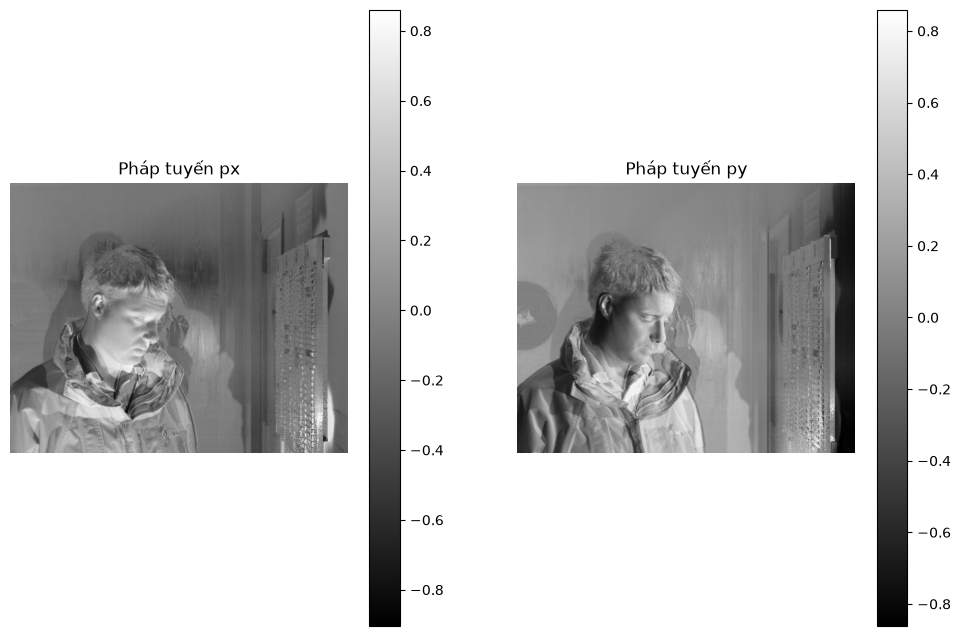

In [18]:
plt.figure(figsize=(12,8))

plt.subplot(1,2,1)
plt.imshow(px, cmap='gray') # Do px, py là ma trận 2 chiều và được chuẩn hóa trong đoạn [0,1] nên có thể hiển thị grayscale
plt.title('Pháp tuyến px')
plt.colorbar()
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(py, cmap='gray') # Do px, py là ma trận 2 chiều và được chuẩn hóa trong đoạn [0,1] nên có thể hiển thị grayscale
plt.title('Pháp tuyến py')
plt.colorbar()
plt.axis('off')

plt.show()
# Các giá trị px, py nằm trong khoảng [-1;1]

pz tuân theo định lý Pythagoras từ px và py.


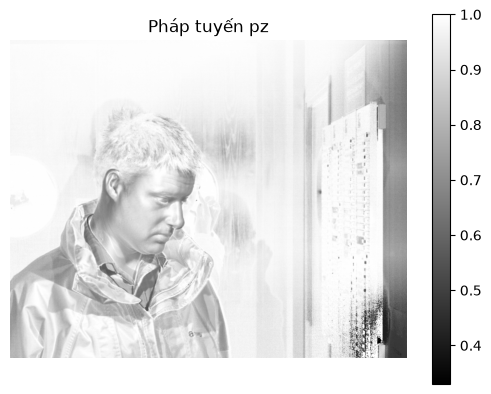

In [19]:
pz_computed = np.sqrt(1 - (px**2 + py**2))

# So sánh với giá trị pz thực tế
if np.allclose(pz, pz_computed):
    print("pz tuân theo định lý Pythagoras từ px và py.")
else:
    print("pz không tuân theo định lý Pythagoras từ px và py.")

# Kết luận: Bản thân 1 vector trong hệ gradient space được biểu diễn bởi (px,py) và ánh xạ duy nhất đến 1 vector trong không gian Oxyz nên không cần có pz. pz được suy ra từ px và py, trong dataset họ tính thêm vào

plt.imshow(pz, cmap='gray')
plt.title('Pháp tuyến pz')
plt.colorbar()
plt.axis('off')
plt.show()

In [20]:
print(px.dtype, py.dtype, pz.dtype)

float64 float64 float64


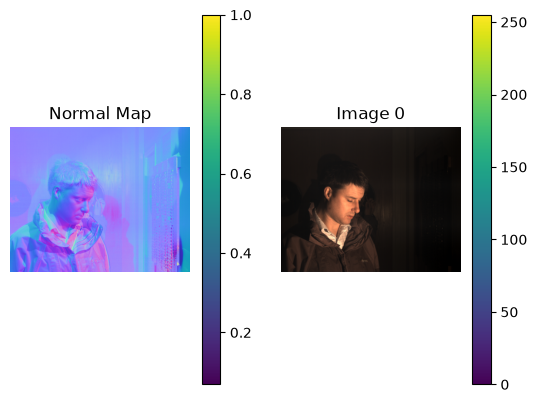

In [21]:
normal_map = cv2.merge([pz, -px, py])

# Chuẩn hóa các giá trị vector vào khoảng [0, 1] 
# Khi chuẩn hóa về [0, 1], dữ liệu sẽ phù hợp với nhiều mô hình học sâu hơn, đặc biệt là các mô hình CNN. 
#   Vì hầu hết các mô hình đều giả định input là ảnh RGB có giá trị trong khoảng [0,1] hoặc [0, 255]
#   Các hàm Relu sẽ hoạt động tốt hơn khi dữ liệu không có giá trị âm
#   Dễ dàng tích hợp với các pipeline xử lý ảnh tiêu chuẩn
# Giữ nguyên [-1,1]
#   Giữ lại thông tin normal map 1 cách chuẩn xác hơn, thậm chí trong quá trình check ảnh có thể nhìn ảnh đẹp/rõ ràng hơn. Nhưng tóm lại khi vào model nó vẫn là tensor.
#   Không thích hợp để fine-tunining mô hình đã được pre-trained. Vì đa số mặc định đầu vào khi train không có số dương,

# Ánh xạ từ [-1, 1] sang [0,1]
normal_map = (normal_map + 1) / 2
normal_map_16bit = np.round(normal_map * 65535).astype(np.uint16)

cv2.imwrite("./normalmap.png", normal_map_16bit)

normal_map= cv2.imread('./normalmap.png', cv2.IMREAD_UNCHANGED)
normal_map_rgb = cv2.cvtColor(normal_map, cv2.COLOR_BGR2RGB)
normal_map_display = normal_map_rgb / 65535.0

# pylot không hỗ trợ đọc ảnh exr mà mặc định nó đọc ảnh RGB. Do đó khi gặp các biến âm, matplotlib tự động bỏ hoặc làm gì đó.
# Do đó visualize ảnh exr thường không cho cái nhìn chính xác mà ta phải cài tool và đọc ảnh bên ngoài.
plt.subplot(1,2,1)
plt.imshow(normal_map_display)
plt.title('Normal Map')
plt.colorbar()
plt.axis('off')

img0_path = os.path.join(dir_path, 'im0.bmp')
img0 = cv2.imread(img0_path)

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img0, cv2.COLOR_BGR2RGB))
plt.axis('off') # Tắt trục tọa độ
plt.title('Image 0')
plt.colorbar()

plt.show()

## Deepmap

In [22]:
print(z)
print(np.min(z))
print(np.max(z))
print(np.shape(z))
print(z.dtype)

[[ 97.24832743  97.12931077  97.0235971  ...  83.60474318  84.26945761
   85.09649015]
 [ 97.36500411  97.22197956  97.11503564 ...  84.19494806  84.91054676
   85.80638792]
 [ 97.47386193  97.31249397  97.19091971 ...  84.71789673  85.4894059
   86.3959718 ]
 ...
 [ 90.0188167   90.4249327   90.74472264 ... 108.50967013 109.31975776
  110.43851281]
 [ 90.30586856  90.71885115  91.0011592  ... 107.95966974 108.65273181
  109.67008609]
 [ 90.69523714  91.02798942  91.27627361 ... 107.31487507 107.90967644
  108.73174481]]
0.0
197.88901534713196
(1024, 1280)
float64


0
198
(1024, 1280)


[ WARN:0@93.606] global loadsave.cpp:1089 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.


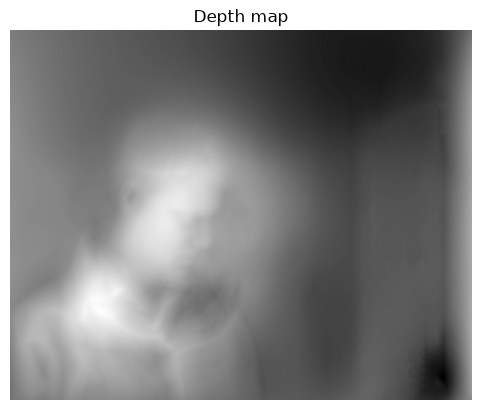

In [23]:
# Kết luận: Deepth map Z là ma trận 2 chiều có shape bằng size của ảnh. Giá trị nhỏ nhất của deepth map là 0, nghĩa là mốc được chọn làm mốc để tính tích phân là pixel có độ sâu thấp nhất.
cv2.imwrite('./deepmap.png', z)

dep = cv2.imread('./deepmap.png', cv2.IMREAD_UNCHANGED)

print(np.min(dep))
print(np.max(dep))
print(np.shape(dep))

plt.imshow(dep, cmap='gray')
plt.title('Depth map')
plt.axis('off')

plt.show()

Tập dataset này chọn 0 làm mốc của deepmap

## Albedo

0.0
267.7663322029443
(1024, 1280)
float64
0
255
(1024, 1280)


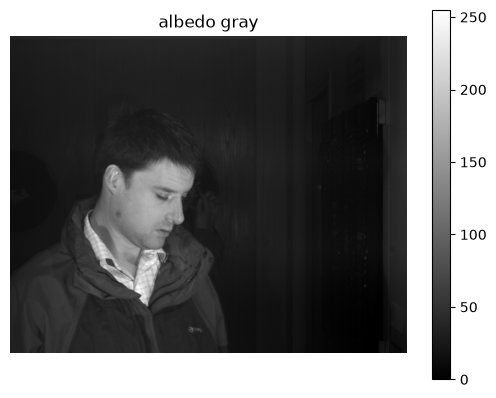

In [24]:
print(np.min(albedo))
print(np.max(albedo))
print(np.shape(albedo))
print(albedo.dtype)

cv2.imwrite('./albedo.png', albedo)

albedo = cv2.imread('./albedo.png', cv2.IMREAD_UNCHANGED)

print(np.min(albedo))
print(np.max(albedo))
print(np.shape(albedo))

plt.imshow(albedo, cmap='gray')
plt.title('albedo gray')
plt.axis('off')
plt.colorbar()
plt.show()

## Kết luận

1. Dữ liệu raw ban đầu gồm 453 folder của 453 người. Trong mỗi folder gồm
    - 4 ảnh bmp đến từ 4 nguồn sáng khác nhau. Thông tin hướng nguồn sáng lần lượt nằm trong file LightSource.m
    - LightSource.m: Hướng nguồn sáng chụp các ảnh bmp
    - albedo.mat: Tái tạo albedo
    - sn.mat: Chứa 3 chiều px, py, pz để tái tạo lên normalmap. px và py thuộc [-1,1]
    - z.mat: Độ sâu của mỗi điểm ảnh. Phục vụ tái tạo deepmap. Không có min-max, phụ thuộc vào việc chọn mốc 
    - metadata.txt: tọa độ 9 điểm landmark trong hình.
2. Ngoài 453 folder trên còn 1 file metadata_all.txt chứa các thông tin bổ sung.
    - id: Nhận diện danh tính (số id bằng số session)
    - gender: Giới tính
    - spectacles: Kính
    - facial_hair: Râu
    - pose: Tư thế
    - quality: Chất lượng
    - Occlusion: Mờ
    - Emotion: Cảm xúc

# 2.Meidapipe

## 2.1. Xác định Landmarks

In [25]:
albedo = cv2.imread(albedo_path, cv2.IMREAD_UNCHANGED)

In [29]:
albedo.shape

(1024, 1280)

Ảnh MediaPipe: shape=(1024, 1280, 3), dtype=uint8
Max=255, Min=0


W0000 00:00:1792548347.361352   34329 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792548347.379227   34335 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792548347.392502   34335 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


✅ Phát hiện khuôn mặt thành công!


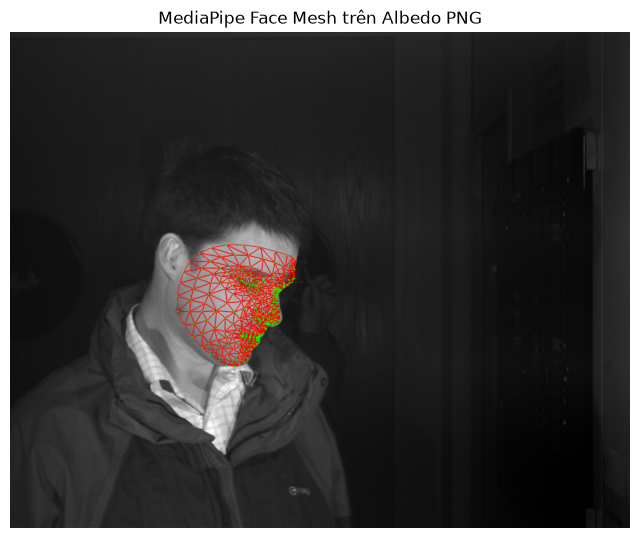

In [27]:
# 1. Khai báo Model Path và Options 
MODEL_PATH = 'face_landmarker.task'
base_options = python.BaseOptions(model_asset_path=MODEL_PATH)
options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    output_face_blendshapes=False,
    output_facial_transformation_matrixes=False,
    num_faces=1,
    min_face_detection_confidence=0.1,  
    min_face_presence_confidence=0.1
)

# 2. Đọc trực tiếp từ file .png
albedo_path = '../Photometric_DB/2205/2007-12-06_14-08-00/albedo.png'
albedo = cv2.imread(albedo_path, cv2.IMREAD_UNCHANGED)

if albedo is None:
    raise FileNotFoundError(f'Không đọc được ảnh: {albedo_path}')

# 3. Chuyển ảnh về uint8
if albedo.dtype == np.uint16:
    # Tương đương ánh xạ dải 16-bit sang 8-bit
    image_uint8 = (albedo / 257).astype(np.uint8)
elif albedo.dtype == np.uint8:
    image_uint8 = albedo.copy()
else:
    raise TypeError(f'Kiểu dữ liệu PNG không được hỗ trợ: {albedo.dtype}')

# 4. Chuẩn hóa số kênh thành RGB
if image_uint8.ndim == 2:
    # Ảnh xám 1 kênh
    rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_GRAY2RGB)
elif image_uint8.ndim == 3 and image_uint8.shape[2] == 3:
    # OpenCV đọc ảnh màu theo thứ tự BGR
    rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGR2RGB)
elif image_uint8.ndim == 3 and image_uint8.shape[2] == 4:
    rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGRA2RGB)
else:
    raise ValueError(f'Kích thước ảnh không được hỗ trợ: {image_uint8.shape}')

# 5. Tạo ảnh đầu vào MediaPipe và ảnh dùng để vẽ
rgb_image = np.ascontiguousarray(rgb_image)
overlay = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2BGR)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_image
)

print(f'Ảnh MediaPipe: shape={rgb_image.shape}, dtype={rgb_image.dtype}')
print(f'Max={np.max(rgb_image)}, Min={np.min(rgb_image)}')

# 6. Phát hiện khuôn mặt
with vision.FaceLandmarker.create_from_options(options) as landmarker:
    results = landmarker.detect(mp_image)
    
# 7. Hiển thị kết quả
if not results.face_landmarks:
    print('❌ MediaPipe không phát hiện được khuôn mặt.')

    plt.figure(figsize=(6, 6))
    plt.imshow(rgb_image)
    plt.title('Ảnh Albedo PNG đầu vào')
    plt.axis('off')
    plt.show()

else:
    print('✅ Phát hiện khuôn mặt thành công!')

    face_landmarks = results.face_landmarks[0]
    h, w = rgb_image.shape[:2]

    landmark_points = [
        (int(round(lm.x * w)), int(round(lm.y * h)))
        for lm in face_landmarks
    ]

    # Vẽ lưới landmark màu đỏ
    for connection in vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION:
        s, e = connection.start, connection.end

        if s < len(landmark_points) and e < len(landmark_points):
            cv2.line(
                overlay,
                landmark_points[s],
                landmark_points[e],
                (0, 0, 255),
                1,
                lineType=cv2.LINE_AA
            )

    # Vẽ các điểm landmark màu xanh lá
    for x, y in landmark_points:
        cv2.circle(
            overlay,
            (x, y),
            1,
            (0, 255, 0),
            -1,
            lineType=cv2.LINE_AA
        )

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title('MediaPipe Face Mesh trên Albedo PNG')
    plt.axis('off')
    plt.show()

1. 3D mesh là cấu trúc dữ liệu mô tả bề mặt của một đối tượng 3 chiều trong không gian. Được mô tả bởi 3 yếu tố:
- Vertices (Đỉnh): Các điểm tọa độ $(x, y, z)$ trong không gian 3D.
- Edges (Cạnh): Các đoạn thẳng nối 2 đỉnh lại với nhau.
- Faces (Mặt): Các bề mặt phẳng được tạo thành bởi nhiều cạnh khép kín (thường là tam giác - Triangles hoặc tứ giác - Quads).
MediaPipe giúp xác định khoảng 468 -> 478 tọa độ 3D landmarks trên khuôn mặt theo thời gian thực từ 1 ảnh 2D thông thường. Ứng dụng thực tế
- Kính thực tế ảo tăng cường
- Xoay hướng mặt 3D, căn chỉnh góc mặt (tùy trường hợp)
- Đánh giá biểu cảm
2. Không thể quay được khuôn mặt khi:
- Góc quay đầu vượt quá 60, 90 độ (nhìn nghiêng hoàn toàn), một nửa khuôn mặt bị khuất. Nhìn từ góc 2D, nửa mặt bị khuất không còn pixel nào. Kể cả khi mô hình ML "đoán" được tọa độ landmarks 3D ở phần bị khuất, thuật toán xoay ảnh (Warping/Texture Mapping) cũng không có dữ liệu bề mặt (Texture) để đắp vào nửa mặt còn lại. Kết quả ảnh sau khi xoay sẽ bị biến dạng kéo vệt (stretching) hoặc bị rỗng.
- Bị che khuất bởi vật thể ngoài (Khẩu trang, kính râm đen, tay che mặt, tóc xõa che mất mắt/mũi/miệng). Khi mất các landmark cốt lõi (như chóp mũi, khóe mắt, khóe miệng), thuật toán giải bài toán Pose Estimation (như PNP - Perspective-n-Point) sẽ tính ra góc xoay bị lệch hoàn toàn. Việc "nội suy" hoặc "phục hồi" vùng bị che phủ mà không có dữ liệu gốc sẽ làm khuôn mặt bị biến dạng hoàn toàn.
- Ảnh quá mờ, nhiễu nặng. Các ảnh có độ phân giải thấp hoặc bị mờ do chuyển động. Landmarks dự đoán lúc này bị sai lệch vị trí rất nặng (jitter/drift). Chỉ cần tọa độ 3D landmark bị lệch vài pixel, ma trận xoay (Rotation Matrix) sẽ bị sai góc hoàn toàn, dẫn đến mặt xoay ra bị bóp méo hình dạng (distorted mesh).
- Biểu cảm quá dị biệt (Extreme Expressions). Ví dụ: Há miệng quá to, nhăn mặt, há há miệng lệch góc... Hầu hết các thuật toán xoay 3D baseline dựa trên một Mô hình 3D chuẩn (3D Canonical Shape / 3MM) cố định ở trạng thái thả lỏng (neutral). Khi biểu cảm quá biến dạng, khoảng cách giữa các landmarks bị lệch so với khung 3D chuẩn, khiến việc khớp (fitting) ma trận xoay bị lệch.

# 3. Ước lượng Pose

# 3.1. Dùng opencv detect pose

1. Hiểu về landmarks mediapipe trả về
    - Mediapipe giúp detect ra các facelandmark của khuôn mặt. Mỗi điểm detect ra có tọa độ x,y,z
    - x: Vị trí theo chiều ngang của khuôn mặt
    - y: Vị trí theo chiều dọc của khuôn mặt
    - z: giá trị độ sâu tương đối do Face Mesh ước lượng, không phải khoảng cách thực tế tính bằng mét.
    - Trong đó x và y trả về tọa độ chuẩn hóa theo kích thước ảnh. Chẳng hạn, x = 0.5 tương ứng khoảng giữa ảnh theo chiều ngang.

2. Hiểu về Roll Pitch, Yaw

    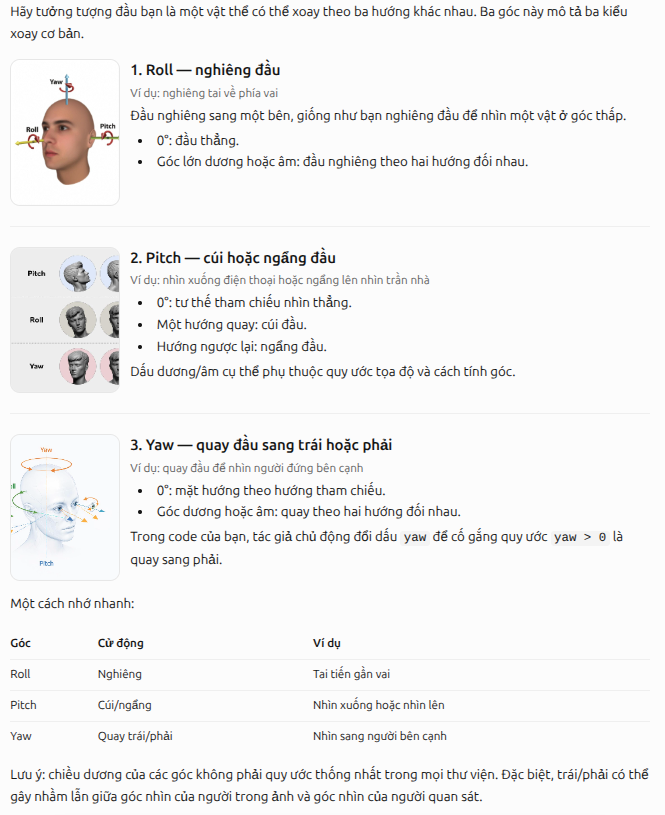

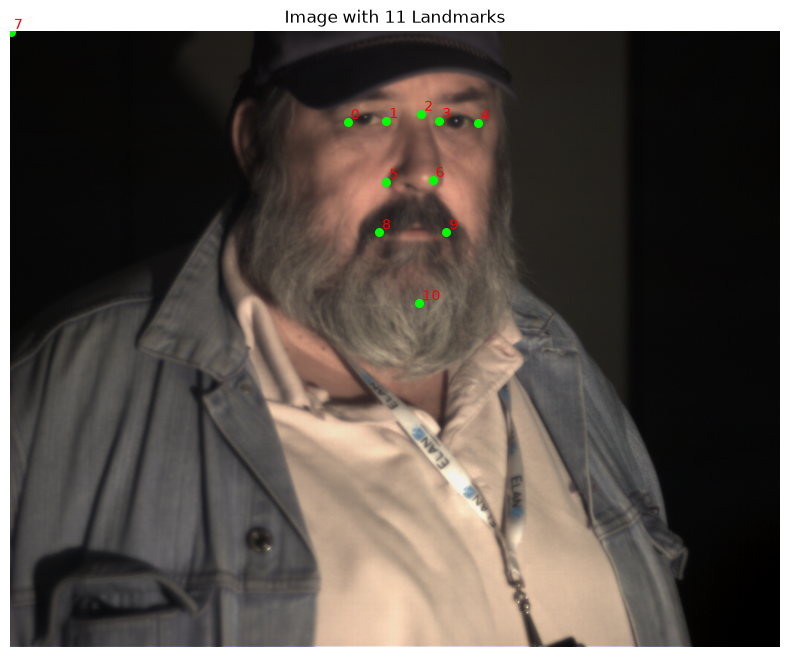


=== KẾT QUẢ ƯỚC LƯỢNG POSE CHÍNH XÁC ===
Pitch (Gật đầu Lên [+]/Xuống [-]) : -54.26 độ
Yaw   (Quay đầu Trái [+]/Phải [-]) : 76.90 độ
Roll  (Nghiêng đầu Trái/Phải)      : -46.70 độ


In [31]:
# 1. Đọc dữ liệu từ file metadata.txt
session_path = '../Photometric_DB/1100/2009-06-26_07-16-26'
metadata_path = os.path.join(session_path, 'metadata.txt')
image_path = os.path.join(session_path, 'im0.bmp')

with open(metadata_path, 'r') as f:
    line = f.readline().strip()
    data = [float(x) for x in line.split()]

# Lấy 22 số đầu tiên tương ứng với 11 cặp tọa độ (x, y)
landmarks_2d = []
for i in range(0, 22, 2):
    x = int(data[i])
    y = int(data[i+1])
    landmarks_2d.append([x, y])

landmarks_2d = np.array(landmarks_2d, dtype=np.float32)

# 2. Đọc ảnh gốc và vẽ các điểm mốc để kiểm tra
img = cv2.imread(image_path)
h, w, c = img.shape

# Chuyển BGR sang RGB để hiển thị đúng màu trong Matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Hiển thị ảnh gốc
plt.figure(figsize=(10, 8))
plt.imshow(img_rgb)

# Vẽ 11 điểm landmark và đánh số từ 0 đến 10
for idx, point in enumerate(landmarks_2d):
    cx, cy = int(point[0]), int(point[1])

    plt.scatter(cx, cy, s=30, c='lime')
    plt.text(
        cx + 5, cy - 5,
        str(idx),
        color='red',
        fontsize=10
    )

plt.title('Image with 11 Landmarks')
plt.axis('off')
plt.show()


# ==========================================
# 3. ƯỚC LƯỢNG POSE CHUẨN (ĐÃ KHỚP THỨ TỰ LANDMARK PHOTOFACE)
# ==========================================

# Cấu trúc điểm 3D chuẩn dựa trên mô hình Anthropometric khuôn mặt (Đơn vị: mm)
# Gốc tọa độ (0, 0, 0) được đặt tại Điểm số 6 (Đỉnh chóp mũi)
model_points = np.array([
    (-45.0,  40.0, -45.0),  # Điểm 0: Khóe ngoài mắt phải
    (-15.0,  40.0, -25.0),  # Điểm 1: Khóe trong mắt phải
    (  0.0,  42.0, -20.0),  # Điểm 2: Gốc mũi (Ấn đường)
    ( 15.0,  40.0, -25.0),  # Điểm 3: Khóe trong mắt trái
    ( 45.0,  40.0, -45.0),  # Điểm 4: Khóe ngoài mắt trái
    (-20.0,  10.0, -15.0),  # Điểm 5: Cánh mũi phải
    (  0.0,   0.0,   0.0),  # Điểm 6: ĐÀNH MŨI (CHÓP MŨI) - Gốc tọa độ
    ( 20.0,  10.0, -15.0),  # Điểm 7: Cánh mũi trái
    (-30.0, -35.0, -30.0),  # Điểm 8: Khóe miệng phải
    ( 30.0, -35.0, -30.0)   # Điểm 9: Khóe miệng trái
], dtype=np.float32)

# Lấy chính xác 10 điểm đầu tiên từ metadata (bỏ điểm số 10 ở góc màn hình)
image_points = landmarks_2d[0:10] 

# Tiêu cự camera giả định (Thông số h, w lấy từ img.shape)
focal_length = w
center = (w / 2, h / 2)
camera_matrix = np.array([
    [focal_length, 0, center[0]],
    [0, focal_length, center[1]],
    [0, 0, 1]
], dtype=np.float32)

dist_coeffs = np.zeros((4, 1))  # Không tính méo ống kính

# Giải PnP bằng thuật toán EPnP hoặc Iterative để tăng độ chính xác góc xoay
success, rvec, tvec = cv2.solvePnP(model_points, image_points, camera_matrix, dist_coeffs, flags=cv2.SOLVEPNP_EPNP)

if success:
    # Chuyển đổi Rotation Vector sang Ma trận xoay (Rotation Matrix)
    rmat, _ = cv2.Rodrigues(rvec)
    
    # Tính các góc Euler theo hệ trục chuẩn OpenCV (X: Pitch, Y: Yaw, Z: Roll)
    sy = np.sqrt(rmat[0, 0] * rmat[0, 0] + rmat[1, 0] * rmat[1, 0])
    singular = sy < 1e-6

    if not singular:
        x = np.arctan2(rmat[2, 1], rmat[2, 2])
        y = np.arctan2(-rmat[2, 0], sy)
        z = np.arctan2(rmat[1, 0], rmat[0, 0])
    else:
        x = np.arctan2(-rmat[1, 2], rmat[1, 1])
        y = np.arctan2(-rmat[2, 0], sy)
        z = 0

    # Chuyển đổi từ Radian sang Độ và chuẩn hóa khoảng góc
    pitch = np.degrees(x)
    yaw = np.degrees(y)
    roll = np.degrees(z)

    # Hiệu chỉnh góc về khoảng trực quan (-180 đến 180) nếu cần
    if pitch > 90: pitch -= 180
    elif pitch < -90: pitch += 180

    print("\n=== KẾT QUẢ ƯỚC LƯỢNG POSE CHÍNH XÁC ===")
    print(f"Pitch (Gật đầu Lên [+]/Xuống [-]) : {pitch:.2f} độ")
    print(f"Yaw   (Quay đầu Trái [+]/Phải [-]) : {yaw:.2f} độ")
    print(f"Roll  (Nghiêng đầu Trái/Phải)      : {roll:.2f} độ")

File metadata.txt trong dataset raw chứa landmark của 11 điểm. Tuy nhiên có 1 session ../Photometric_DB/1001/2008-02-23_12-21-31 điểm thứ 11 ko phải ở cằm. Do đó code dựa vào 10 điểm còn lại đưa để đưa vào phép tính solvePnP() để tính Pose

# 3.2. Dùng 6DRepNet

- Điểm nổi bật của 6DRepNet là không dự đoán trực tiếp ba góc Euler yaw, pitch, roll ngay ở đầu ra mạng, mà dự đoán một biểu diễn quay 6 chiều, sau đó chuyển đổi biểu diễn này thành ma trận quay 3D.
- Ba góc Euler có thể gây ra những vấn đề khi huấn luyện, đặc biệt với những tư thế quay lớn. Cách biểu diễn góc có tính tuần hoàn và có thể gặp các điểm không liên tục hoặc nhập nhằng khi chuyển đổi giữa những tư thế tương đương.
- Thay vì học ba góc trực tiếp, 6DRepNet học biểu diễn liên tục của phép quay rồi chuyển thành ma trận quay hợp lệ. Đây là ý tưởng trung tâm của bài báo gốc.
- **Hàm model.predict(img) sẽ hoạt động tốt nhất khi ảnh đầu vào là vùng khuôn mặt đã được crop chuẩn (hoặc có truyền bounding box của mặt). Sẽ có sai lệch nếu ảnh là toàn cảnh kích thước lớn mà không crop trước**

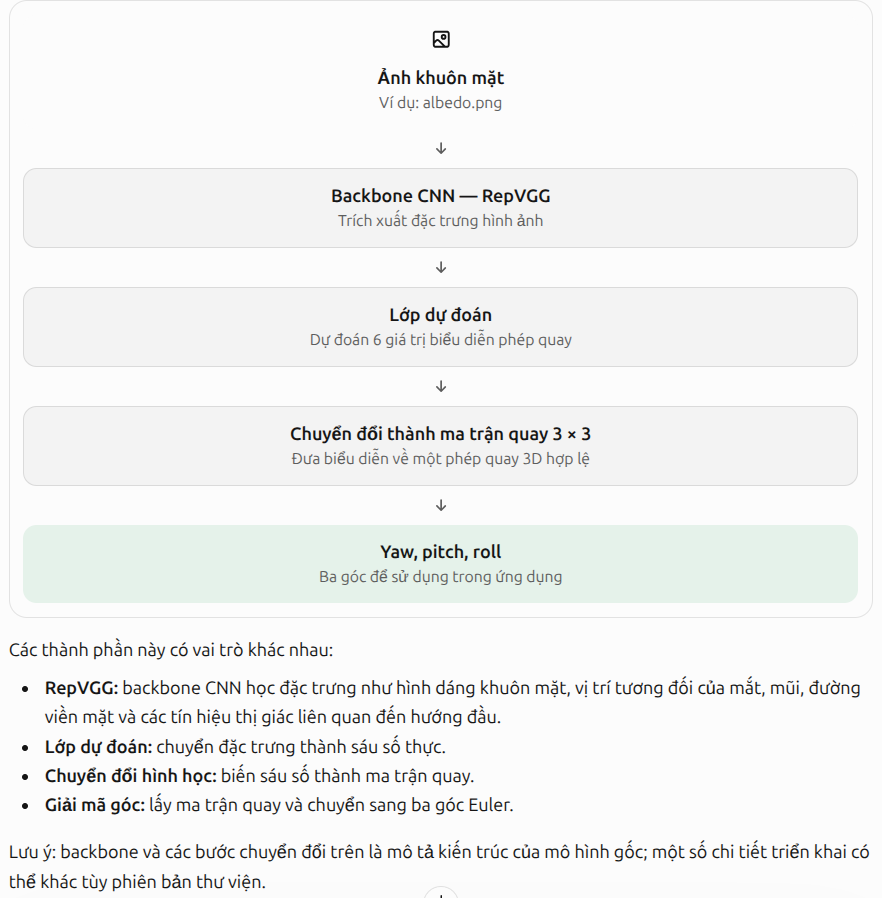

In [40]:
# img_path = '../Photometric_DB/2205/2007-12-06_14-08-00/albedo_crop.png'
img_path = '../Photometric_DB/1004/2008-03-07_15-22-31/albedo_crop.png'

Yaw:   -0.96°
Pitch: -6.67°
Roll:  -1.27°


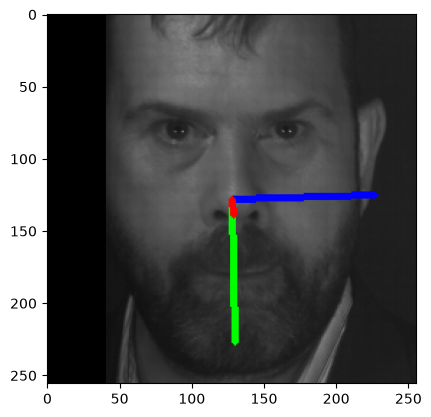

In [41]:
# Khởi tạo model
model = SixDRepNet()

# Đọc ảnh
img = cv2.imread(img_path)

# img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

if img is None:
    raise FileNotFoundError("Không đọc được ảnh!")

# Dự đoán góc
pitch, yaw, roll = model.predict(img)

# Chuyển về scalar float
pitch = float(np.asarray(pitch).reshape(-1)[0])
yaw   = float(np.asarray(yaw).reshape(-1)[0])
roll  = float(np.asarray(roll).reshape(-1)[0])

print(f"Yaw:   {yaw:.2f}°")
print(f"Pitch: {pitch:.2f}°")
print(f"Roll:  {roll:.2f}°")

# Vẽ trục tọa độ lên ảnh
model.draw_axis(img, yaw, pitch, roll)

plt.imshow(img, cmap="gray")
plt.show()

Ảnh MediaPipe: shape=(256, 256, 3), dtype=uint8
Max=246, Min=19


W0000 00:00:1792549781.747781   42320 face_landmarker_graph.cc:180] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1792549781.752885   42322 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792549781.768396   42324 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


✅ Phát hiện khuôn mặt thành công!


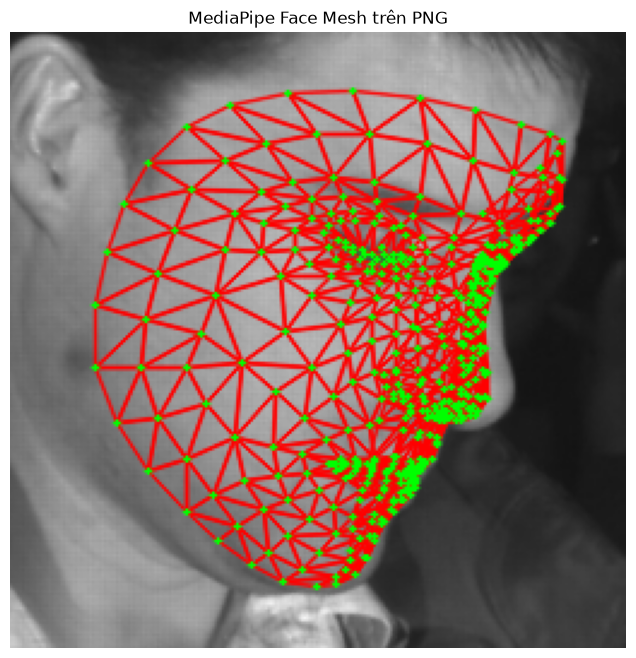

In [33]:
# 1. Khai báo Model Path và Options 
MODEL_PATH = 'face_landmarker.task'
base_options = python.BaseOptions(model_asset_path=MODEL_PATH)
options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    output_face_blendshapes=False,
    output_facial_transformation_matrixes=False,
    num_faces=1,
    min_face_detection_confidence=0.1,  
    min_face_presence_confidence=0.1
)

# 2. Đọc trực tiếp từ file .png
img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)

if img is None:
    raise FileNotFoundError(f'Không đọc được ảnh: {img_path}')

# 3. Chuyển ảnh về uint8
if img.dtype == np.uint16:
    # Tương đương ánh xạ dải 16-bit sang 8-bit
    image_uint8 = (img / 257).astype(np.uint8)
elif img.dtype == np.uint8:
    image_uint8 = img.copy()
else:
    raise TypeError(f'Kiểu dữ liệu PNG không được hỗ trợ: {img.dtype}')

# 4. Chuẩn hóa số kênh thành RGB
if image_uint8.ndim == 2:
    # Ảnh xám 1 kênh
    rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_GRAY2RGB)
elif image_uint8.ndim == 3 and image_uint8.shape[2] == 3:
    # OpenCV đọc ảnh màu theo thứ tự BGR
    rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGR2RGB)
elif image_uint8.ndim == 3 and image_uint8.shape[2] == 4:
    rgb_image = cv2.cvtColor(image_uint8, cv2.COLOR_BGRA2RGB)
else:
    raise ValueError(f'Kích thước ảnh không được hỗ trợ: {image_uint8.shape}')

# 5. Tạo ảnh đầu vào MediaPipe và ảnh dùng để vẽ
rgb_image = np.ascontiguousarray(rgb_image)
overlay = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2BGR)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_image
)

print(f'Ảnh MediaPipe: shape={rgb_image.shape}, dtype={rgb_image.dtype}')
print(f'Max={np.max(rgb_image)}, Min={np.min(rgb_image)}')

# 6. Phát hiện khuôn mặt
with vision.FaceLandmarker.create_from_options(options) as landmarker:
    results = landmarker.detect(mp_image)
    
# 7. Hiển thị kết quả
if not results.face_landmarks:
    print('❌ MediaPipe không phát hiện được khuôn mặt.')

    plt.figure(figsize=(6, 6))
    plt.imshow(rgb_image)
    plt.title('Ảnh PNG đầu vào')
    plt.axis('off')
    plt.show()

else:
    print('✅ Phát hiện khuôn mặt thành công!')

    face_landmarks = results.face_landmarks[0]
    h, w = rgb_image.shape[:2]

    landmark_points = [
        (int(round(lm.x * w)), int(round(lm.y * h)))
        for lm in face_landmarks
    ]

    # Vẽ lưới landmark màu đỏ
    for connection in vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION:
        s, e = connection.start, connection.end

        if s < len(landmark_points) and e < len(landmark_points):
            cv2.line(
                overlay,
                landmark_points[s],
                landmark_points[e],
                (0, 0, 255),
                1,
                lineType=cv2.LINE_AA
            )

    # Vẽ các điểm landmark màu xanh lá
    for x, y in landmark_points:
        cv2.circle(
            overlay,
            (x, y),
            1,
            (0, 255, 0),
            -1,
            lineType=cv2.LINE_AA
        )

    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title('MediaPipe Face Mesh trên PNG')
    plt.axis('off')
    plt.show()

In [35]:
if results.face_landmarks:
  face_landmarks = results.face_landmarks[0]
  h, w = rgb_image.shape[:2]

  # Chuyển đổi tọa độ pixel
  points = np.array(
      [(int(lm.x * w), int(lm.y * h)) for lm in face_landmarks], dtype=np.float32
  )

  # Lấy tọa độ các điểm mốc quan trọng để đo độ lệch/quay ngang:
  nose_tip = points[1]  # Chóp mũi
  left_cheek = points[234]  # Má/viền trái
  right_cheek = points[454]  # Má/viền phải

  # Tính khoảng cách từ chóp mũi đến má trái và má phải
  dist_left = np.linalg.norm(nose_tip - left_cheek)
  dist_right = np.linalg.norm(nose_tip - right_cheek)

  # Tránh lỗi chia cho 0
  if dist_right > 0 and dist_left > 0:
    # Tính tỷ lệ khoảng cách 2 bên
    ratio = max(dist_left, dist_right) / min(dist_left, dist_right)

    print(f'Khoảng cách mũi-má trái: {dist_left:.1f}px')
    print(f'Khoảng cách mũi-má phải: {dist_right:.1f}px')
    print(f'Tỷ lệ mất đối xứng (Asymmetry Ratio): {ratio:.2f}')

    # Đặt ngưỡng (Threshold): Nếu tỷ lệ lớn hơn 2.5 hoặc 3.0 nghĩa là mặt quay ngang sâu / mất nửa mặt
    THRESHOLD_RATIO = 2.5
    if ratio > THRESHOLD_RATIO:
      print(
          '⚠️ CẢNH BÁO: Ảnh này bị quay ngang sâu / mất nửa mặt (Deep'
          ' Profile)!'
      )
      # Tại đây bạn có thể viết thêm code move/copy file ảnh này vào thư mục "filtered_out"
    else:
      print('✅ Ảnh có góc nhìn bình thường (gần trực diện hoặc nghiêng ít).')
  else:
    print('⚠️ Không xác định được khoảng cách landmark.')
else:
  print('❌ MediaPipe không phát hiện được khuôn mặt.')

Khoảng cách mũi-má trái: 167.4px
Khoảng cách mũi-má phải: 56.3px
Tỷ lệ mất đối xứng (Asymmetry Ratio): 2.97
⚠️ CẢNH BÁO: Ảnh này bị quay ngang sâu / mất nửa mặt (Deep Profile)!


✅ Phát hiện khuôn mặt thành công! Tiến hành crop...
Tâm mũi tại: (190, 158) trên ảnh gốc 256x256
⚠️ Vùng crop vượt biên. Thêm padding: L=0, T=32, R=124, B=92


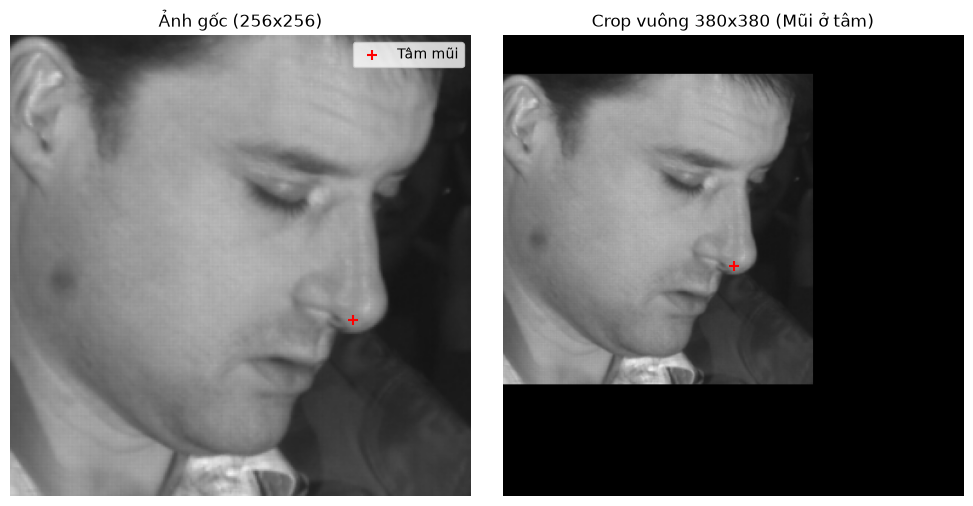

In [37]:
CROP_SIZE = 380
if not results.face_landmarks:
    print('❌ MediaPipe không phát hiện được khuôn mặt để crop.')
else:
    print('✅ Phát hiện khuôn mặt thành công! Tiến hành crop...')
    face_landmarks = results.face_landmarks[0]
    h_orig, w_orig = rgb_image.shape[:2]

    # --- Lấy tọa độ tâm mũi (Nose Tip - Index 1) ---
    nose_landmark = face_landmarks[1]
    nose_x = int(nose_landmark.x * w_orig)
    nose_y = int(nose_landmark.y * h_orig)
    print(f'Tâm mũi tại: ({nose_x}, {nose_y}) trên ảnh gốc {w_orig}x{h_orig}')

    # --- Tính toán vùng Crop vuông sao cho mũi ở tâm ---
    # Tính toán tọa độ Top-Left của hình vuông
    half_size = CROP_SIZE // 2
    x1 = nose_x - half_size
    y1 = nose_y - half_size
    x2 = x1 + CROP_SIZE
    y2 = y1 + CROP_SIZE

    # --- Xử lý biên (Padding) nếu vùng crop vượt ra ngoài ảnh gốc ---
    # Padding cần thiết cho 4 cạnh
    pad_left = max(0, -x1)
    pad_top = max(0, -y1)
    pad_right = max(0, x2 - w_orig)
    pad_bottom = max(0, y2 - h_orig)

    # Thêm padding màu đen vào ảnh gốc (nếu cần)
    if pad_left > 0 or pad_top > 0 or pad_right > 0 or pad_bottom > 0:
        print(f'⚠️ Vùng crop vượt biên. Thêm padding: L={pad_left}, T={pad_top}, R={pad_right}, B={pad_bottom}')
        # OpenCV dùng order B, T, L, R cho padding
        padded_image = cv2.copyMakeBorder(
            rgb_image, pad_top, pad_bottom, pad_left, pad_right, 
            cv2.BORDER_CONSTANT, value=[0, 0, 0] # Màu đen cho ảnh RGB uint8
        )
        # Điều chỉnh lại tọa độ crop trên ảnh đã được padded
        crop_x1 = x1 + pad_left
        crop_y1 = y1 + pad_top
        crop_x2 = crop_x1 + CROP_SIZE
        crop_y2 = crop_y1 + CROP_SIZE
        
        # Crop trên ảnh có padding
        square_crop = padded_image[crop_y1:crop_y2, crop_x1:crop_x2]
    else:
        # Không cần padding, crop trực tiếp
        square_crop = rgb_image[y1:y2, x1:x2]

    # ==========================================
    # 3. Hiển thị kết quả
    # ==========================================
    plt.figure(figsize=(10, 5))
    
    # Hiển thị ảnh gốc
    plt.subplot(1, 2, 1)
    plt.imshow(rgb_image)
    plt.scatter(nose_x, nose_y, c='red', s=50, marker='+', label='Tâm mũi')
    plt.title(f'Ảnh gốc ({w_orig}x{h_orig})')
    plt.axis('off')
    plt.legend()

    # Hiển thị ảnh crop vuông
    plt.subplot(1, 2, 2)
    plt.imshow(square_crop)
    # Vẽ marker tâm mũi trên ảnh crop (luôn ở chính giữa)
    plt.scatter(CROP_SIZE//2, CROP_SIZE//2, c='red', s=50, marker='+') 
    plt.title(f'Crop vuông {CROP_SIZE}x{CROP_SIZE} (Mũi ở tâm)')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

Yaw:   -39.19°
Pitch: -40.98°
Roll:  32.46°


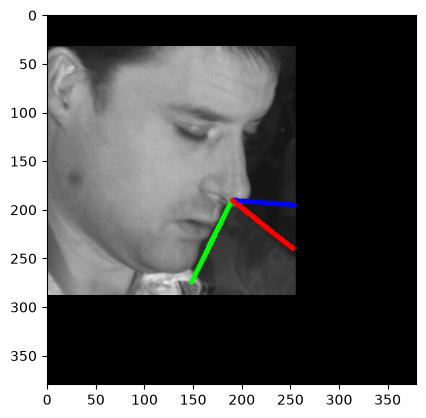

In [ ]:
# Dự đoán góc
pitch, yaw, roll = model.predict(square_crop)

# Chuyển về scalar float
pitch = float(np.asarray(pitch).reshape(-1)[0])
yaw   = float(np.asarray(yaw).reshape(-1)[0])
roll  = float(np.asarray(roll).reshape(-1)[0])

print(f"Yaw:   {yaw:.2f}°")
print(f"Pitch: {pitch:.2f}°")
print(f"Roll:  {roll:.2f}°")

# Vẽ trục tọa độ lên ảnh
model.draw_axis(square_crop, yaw, pitch, roll)

plt.imshow(square_crop, cmap="gray")
plt.show()

- Đã thử nghiệm với 4 ảnh bmp và albedo. Kết quả sơ bộ cho thấy detect trên ảnh albedo cho kết quả tốt hơn.
- **Bắt buộc phải crop mặt kết quả mới chính xác**
- **Cho dù crop ảnh sao cho tâm mũi ở trung tâm ảnh hay crop bình thường thì kết quả 6Drepnet chênh lệch ko đáng kể.**
- **Khi ảnh quay ngang quá sâu (yaw) thì góc detect ko đúng và có thể lệch => Loại bỏ**

# 3.3. 3DDFA_V2

In [26]:
!git clone https://github.com/cleardusk/3DDFA_V2.git

Cloning into '3DDFA_V2'...
remote: Enumerating objects: 706, done.
remote: Counting objects: 100% (266/266), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 706 (delta 219), reused 204 (delta 204), pack-reused 440 (from 1)
Receiving objects: 100% (706/706), 74.77 MiB | 5.08 MiB/s, done.
Resolving deltas: 100% (378/378), done.


**Không dựng được do lệch phiên bản python**